In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
import thinkstats2
import thinkplot
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
import scipy.stats as ss

import statsmodels.formula.api as sm

# Central Limit Theorem and Non-Normal Data

><b>Originally Created by Akeem Semper: [https://github.com/AkeemSemper/Basic_Stats_in_Python_Student_Workbooks](https://github.com/AkeemSemper/Basic_Stats_in_Python_Student_Workbooks "Original Repository")</b>

The Central Limit Theorem is one of the important concepts of statistics, and something that we have addressed in a backdoor way while doing simulations. The definition from Wikipedia states, "In probability theory, the central limit theorem (CLT) establishes that, in many situations, when independent random variables are summed up, their properly normalized sum tends toward a normal distribution even if the original variables themselves are not normally distributed. The theorem is a key concept in probability theory because it implies that probabilistic and statistical methods that work for normal distributions can be applicable to many problems involving other types of distributions."

In more common language, the CLT states:
<ul>
<li>When independent random samples are taken, the distribution of their means approaches normal as more samples are taken. 
<li>The mean of the sample will equal the mean of the population. 
<li>The standard deviation of the sample will equal the standard deviation of the population divided by the root of the sample size.
</ul>

We can use this as a shortcut to help analyze data that is not normal, or where we don't know the distribution. 

#### Load Data

We will use the assessments data from the city as an example. 

In [55]:
#Note: the filter here takes out large values. This works fine either way, but with the large outliers in there, visualizing
#is less effective, due to the range. 
# Also, if a sample includes one $20 property randomly, that will have a big impact. 
df = pd.read_csv("data/Assessments.csv")
df = df[df['Assessed Value']<1000000]
df = df[df['Assessed Value']>20000]
df.sort_values("Assessed Value", ascending=False).head()

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,Latitude,Longitude
5281,1113737,NaN,525.0,SECORD BOULEVARD NW,N,4487.0,SECORD,Ward 1,999500,53.536185,-113.704181
301978,10258057,NaN,4405.0,WINGFIELD CAPE NW,Y,5570.0,WINDERMERE,Ward 9,999500,53.448727,-113.610375
149191,7422108,NaN,11120.0,75 AVENUE NW,Y,5290.0,MCKERNAN,Ward 8,999500,53.511599,-113.517812
325007,10505293,NaN,650.0,HOWATT DRIVE SW,Y,5465.0,HAYS RIDGE AREA,Ward 9,999000,53.420364,-113.568871
304071,10225013,NaN,3333.0,CAMERON HEIGHTS LANDING NW,Y,4466.0,CAMERON HEIGHTS,Ward 5,999000,53.472654,-113.631789


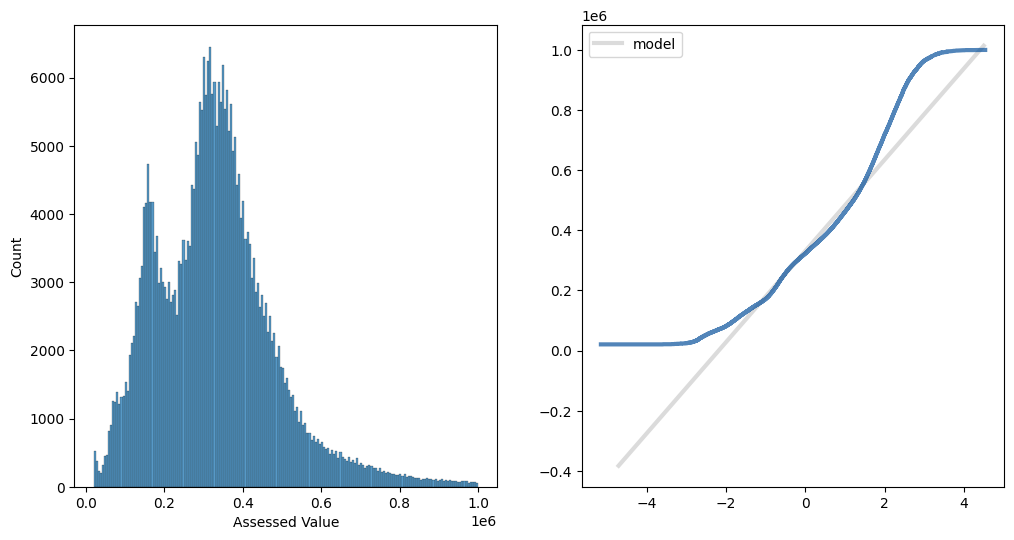

In [56]:
#Visualize Distribution and a normality plot
thinkplot.PrePlot(2,1,2)
sns.histplot(df["Assessed Value"])
thinkplot.SubPlot(2)
thinkstats2.NormalProbabilityPlot(df["Assessed Value"])
thinkplot.Config()

#### Distribution Results

Based on both visualizations, the data is pretty clearly not normal. 

How do we deal with this non-normal data? We have the data of the population here, so we can just calculate it. In reality though, this isn't normally the case. Think about looking at items where we can't capture the population data and are relying on a sample exclusively:
<ul>
<li>The gorilla example from the book, where we can only tranquilize and assess a small fraction of the total populations.
<li>Any survey type data, short of a full census. We only get responses from part of the population.
<li>Scientific measurements, where we have only a few examples.
</ul>

In any of these cases we don't have the distribution of the population, and we really can't get it with confidence in any reasonable way. This is where the CLT comes in handy - we can trust the the results of our samples will be normal, then use that to infer about the entire population. The distribution of the means being normal means that we can rely on all the implicit powers of the normal distribution analytical tools.

We can call back to our estimation days and generate some samples... Each sample will grab n records from the population, calculate the mean of that sample of data, place all of the means into a list, then visualize that distribution of means. 

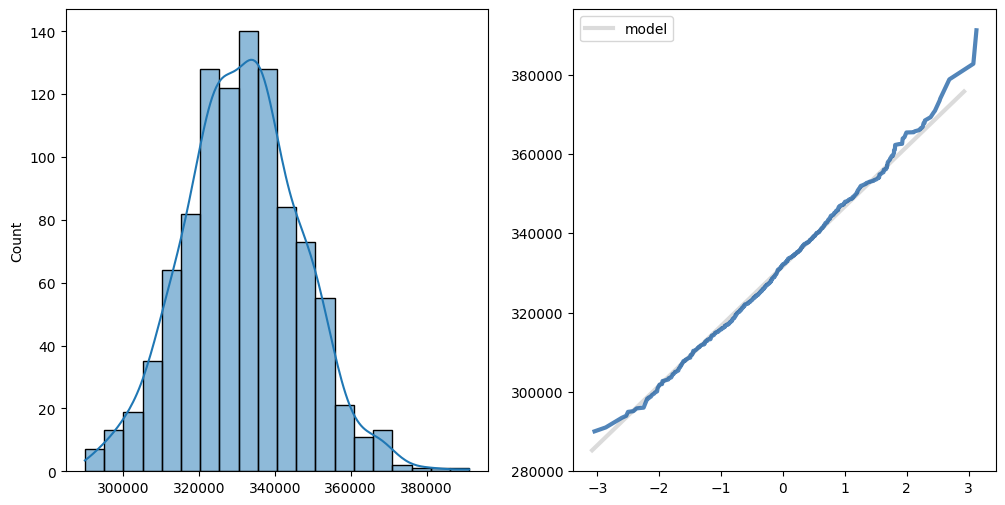

In [57]:
#Take some samples 
i = 0
n = 100
total = 1000
means = []

while i < total:
    tmp = df["Assessed Value"].sample(n)
    means.append(tmp.mean())
    i += 1

thinkplot.PrePlot(2,1,2)
sns.histplot(means, binwidth=5000, kde=True)
thinkplot.SubPlot(2)
thinkstats2.NormalProbabilityPlot(means)
thinkplot.Config()

#### Sampling Results

Taking a bunch of samples delivered us a stack of means. We can run some calculations to see how well we did. The means should be pretty close, that's part of the power of the CLT! The standard deviation of the samples are also the standard error, indicating our expected accuracy. If we increase the n, that SE should go down.

In [58]:
popMean = df["Assessed Value"].mean()
popStd = df["Assessed Value"].std()
estMean = np.mean(means)
estSE = np.std(means)
print("Population Mean:", popMean)
print("Population Std:", popStd)
print("\n")
print("Estimate Mean:", estMean)
print("Estimate SE:", estSE)

Population Mean: 331128.99929439713
Population Std: 151758.4909257068


Estimate Mean: 331666.783
Estimate SE: 15058.044634610133


### Normality status - Increased!

The means of the samples are pretty normal, even if the underlying distribution isn't. The normal distribution is common (hence the normal part), but everything in life isn't normally distributed, as we've seen. 
<ul>
<li> Incomes can often be represented with a lognormal distribution. 
<li> Property assessments here have a bimodal distribution (two humps).
<li> Some things we may want to look at have a distribution that we just don't know at all!
</ul>


### Application of CLT

One place that the CLT is important is in hypothesis testing, most visably in the testing that we did with our simulations. We take repeated samples from the data in each of the loops that we created to do those tests and take the mean of each sample. Statistical tests like the t-test are parametric, assuming the data is normally distributed, and this repeated sample and mean operation ensures that normality assumption is valid. We can use the normal distribution based calculations of the p-value, representing the likelihood of the compared samples being similar due to randomness, because of this fact! This application of the CLT in hypothesis testing is one of the foundations that modern science was built on!!

## CLT in Full Effect

The example above shows the idea behind the CLT - we can take samples and use them to estimate for a population. We are comfortable with this idea from all the estimation stuff. 

The analytical piece of the CLT is also really handy - we can replicate similar results without all the sampling. Taking 100 or 1000 samples presents similar problems to trying to measure the whole population - it can be hard, time consuming, expensive, or impossible. We can build a function that calculates the CLT directly, and compare the results.

In [59]:
#Calculable CLT
def clt(data):
    mean = np.mean(data)
    se = np.std(data) / np.sqrt(len(data))
    return (mean, se)

In [60]:
#Run CLT Calculation with 1 Sample
#Compare with results above
n1 = 100
cltRes = clt(df["Assessed Value"].sample(n1))
print("CLT Mean:", cltRes[0])
print("CLT SE:", cltRes[1])
print("CLT Est Std:", cltRes[1]*np.sqrt(n1))
print("\n")
print("Population Mean:", popMean)
print("Population Std:", popStd)
print("\n")
print("Estimate Mean:", estMean)
print("Estimate SE:", estSE)

CLT Mean: 321305.0
CLT SE: 15645.13006497549
CLT Est Std: 156451.3006497549


Population Mean: 331128.99929439713
Population Std: 151758.4909257068


Estimate Mean: 331666.783
Estimate SE: 15058.044634610133


#### Results

Just like with most things, the larger our sample is, the better we should expect the results to be. We can use this shortcut when we have limited ability to draw samples, and still get usable results. 

In [61]:
#Exercise

#Rerun with a few different N values to see the changes 

<h3>CLT is Quick</h3>

We can run a bunch of simulations like we did while estimating, but this is way quicker!

Try it for some random distribution...

<Axes: ylabel='Count'>

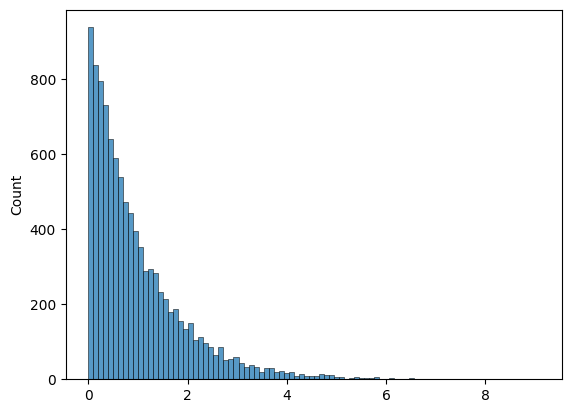

In [62]:
#Generate random Exponential Dist - put into a Series for ease of use later. 
expoDist = pd.Series(ss.expon.rvs(size=10000))
sns.histplot(expoDist)

In [63]:
cltExp = clt(expoDist.sample(n))
print("CLT Mean:", cltExp[0])
print("CLT SE:", cltExp[1])
print("CLT Est Std:", cltExp[1]*np.sqrt(n))
print("\n")
print("Dist Mean:", expoDist.mean())
print("Dist Std:", expoDist.std())

CLT Mean: 0.8651911326717561
CLT SE: 0.0906809323305191
CLT Est Std: 0.906809323305191


Dist Mean: 0.9935157279477141
Dist Std: 0.9800051979775081


That's the magic of the CLT - we can rely on our smallish sample far more than we might think! 

Because this works, we can also harness some of the other useful assumptions of normality, like confidence intervals. Going back to the assessments from above, how confident can we be about our estimate of the mean? What is the 90 confidence interval?

In [64]:
#Directly calculate confidence intervals.
ci1low = ss.norm.ppf(.05, loc=cltRes[0], scale=cltRes[1])
ci1hi = ss.norm.ppf(.95, loc=cltRes[0], scale=cltRes[1])
ci1low, ci1hi

(np.float64(295571.05106849753), np.float64(347038.94893150247))

And if we compare that to the predictions based on estimation?

In [65]:
cdf = thinkstats2.Cdf(means)
cdf.Percentile(.05), cdf.Percentile(.95)

(np.float64(290030.0), np.float64(296005.0))

The exact difference will vary a bit, due to randomness, but we should expect the CI bands to be slightly worse than the estimation example - but we only did one sample! Using the CLT allows us to much more quickly infer about the population when we don't have access to large numbers of samples. 

### Exercise - Try One

Use the CLT to calculate the mean and std from a sample of the salary column below. 

In [66]:
df_sal = pd.read_csv("data/spain_salary.csv")
df_sal.head()

,year,state,gender,statistic,gross_income_euros
0,2017,nationwide,both,mean,23646.50
1,2016,nationwide,both,mean,23156.34
2,2015,nationwide,both,mean,23106.30
3,2014,nationwide,both,mean,22858.17
4,2013,nationwide,both,mean,22697.86


Plot the data, is it normal? 

<Axes: xlabel='gross_income_euros', ylabel='Count'>

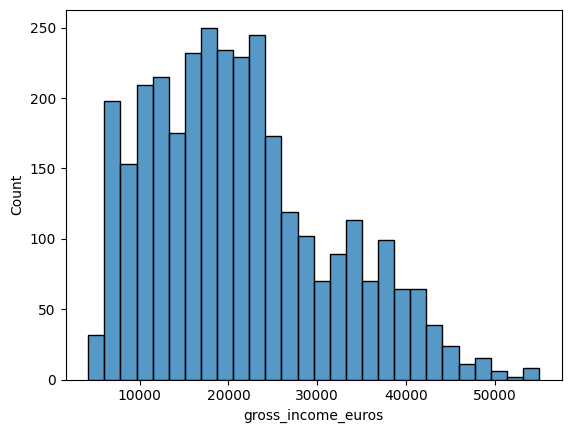

In [67]:
sns.histplot(df_sal["gross_income_euros"])

use CLT to generate mean and std estimates. Compare to a direct calcuation of the population. 

In [68]:
#Use CLT to infer 
cltInc = clt(df_sal["gross_income_euros"].sample(n))
print("CLT Mean:", cltInc[0])
print("CLT SE:", cltInc[1])
print("CLT Est Std:", cltInc[1]*np.sqrt(n))
print("\n")
print("Dist Mean:", df_sal["gross_income_euros"].mean())
print("Dist Std:", df_sal["gross_income_euros"].std())

CLT Mean: 21975.9734
CLT SE: 1070.2095292620809
CLT Est Std: 10702.095292620808


Dist Mean: 21357.35459259259
Dist Std: 10194.037847187145


And the 85% confidence interval?

In [69]:
#Generate 85% CI for salary
#85% = 7.5 to 92.5
ci2low = ss.norm.ppf(.075, loc=cltInc[0], scale=cltInc[1])
ci2hi = ss.norm.ppf(.925, loc=cltInc[0], scale=cltInc[1])
ci2low, ci2hi

(np.float64(20435.373102129004), np.float64(23516.573697870994))

<h1>Common Transformations - Box Cox</h1>

Another strategy to deal with non-normal data is to just do a transformation to make it more normal. We saw this before in one of the sample datasets where we were provided with a log_income value, which changed a lognormal distribution of income into a normal distribution that is easier to analyze. 

These types of transformations are somewhat of a one-off, what makes a distribution normal will differ. One common method is Box-Cox, which raises values to some value - lambda. E.g. if lambda is 2, the original data is squared, if lambda is .5 the original data is square rooted. Lambda can be between -5 and 5. 

This process is something that we can utilize scipy to automate - it will give us back a transformation and the optimal lambda. It tests multiple values of lambda, and determines which is most normal using a normality test. 

In [70]:
#Load some data
def process_time(row):
    
    call_received = datetime.datetime.strptime(row['date_time_received'].split('+')[0], '%Y-%m-%dT%H:%M:%S')
    call_ended    = datetime.datetime.strptime(row['date_time_complete'].split('+')[0], '%Y-%m-%dT%H:%M:%S')
    
    time_ellapsed = call_ended - call_received

    row['Parsed Call Received'] = str(call_received)
    row['Parsed Call Ended'] = str(call_ended)
    row['Time Ellapsed'] = str(time_ellapsed)
    row['Time Ellapsed (minutes)'] = round(time_ellapsed.total_seconds() / 60, 1)

    return row

import requests
import io
import datetime
base_url = 'https://aegis4048.github.io/downloads/notebooks/sample_data/'
filename = '08c32c03-9d88-42a9-b8a1-f493a644b919_NRCEventReporting-Calls-2010.csv'
data = requests.get(base_url + filename).content
df_   = pd.read_csv(io.StringIO(data.decode('utf-8')))

parsed_df = df_.iloc[11000: 12000, :].apply(process_time, axis=1).iloc[:, -4:]
parsed_df['Parsed Call Received'] = pd.to_datetime(parsed_df['Parsed Call Received'], format='%Y-%m-%d %H:%M:%S')
parsed_df['Parsed Call Ended'] = pd.to_datetime(parsed_df['Parsed Call Ended'], format='%Y-%m-%d %H:%M:%S')
parsed_df = parsed_df.sort_values(by = 'Parsed Call Received')

new_parsed_df = parsed_df.drop_duplicates(subset=['Parsed Call Received'], keep=False)
df2 = new_parsed_df.copy()
df2.head()

,Parsed Call Received,Parsed Call Ended,Time Ellapsed,Time Ellapsed (minutes)
11000,2010-05-21 19:32:09,2010-05-21 19:43:35,0:11:26,11.4
11001,2010-05-21 19:54:40,2010-05-21 19:58:40,0:04:00,4.0
11002,2010-05-21 20:03:14,2010-05-21 20:09:11,0:05:57,6.0
11003,2010-05-21 20:04:26,2010-05-21 20:07:39,0:03:13,3.2
11004,2010-05-21 20:18:38,2010-05-21 20:27:45,0:09:07,9.1


<Axes: xlabel='Time Ellapsed (minutes)', ylabel='Count'>

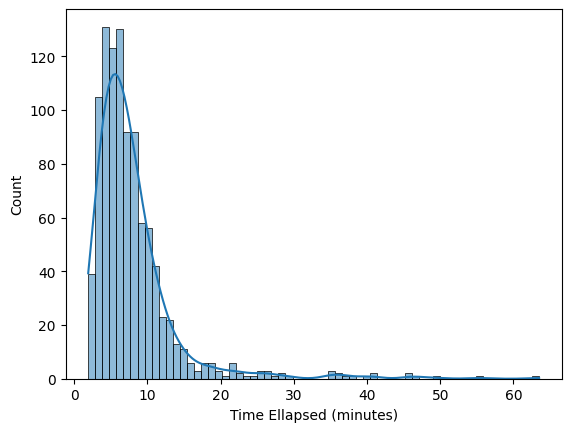

In [71]:
#Visualize call time
calls = pd.Series(df2["Time Ellapsed (minutes)"])
sns.histplot(calls, kde=True)

-0.3217312028383073


<Axes: ylabel='Count'>

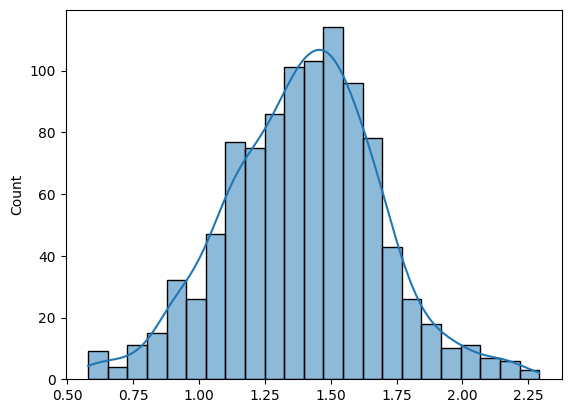

In [72]:
transCalls, lmbda = ss.boxcox(calls)
print(lmbda)
sns.histplot(transCalls, kde=True)

Much more normal!

<h3>Application - Control Charts</h3>

One use of a transformation like this would be to monitor and detect things that fall outside the normal expected bounds. This data is from a call center, we may want to see when calls fall outside a specified range. Going in however, we don't have a cutoff - we can use the distribution to tell us how many are outside of 3std. This is common in lots of quality control/manufacturing types of scenarios. 

The control chart has a normality assumption, because the idea behind it is based off of the standard deviation. We want to "catch" things that are over X standard deviations from normal. If you've heard of Six Sigma, that's based on the same idea - to manufacture things to "six sigmas" of quality (or without error): roughly 99.99966%. This type of transformation to normal for a control chart is a common thing. For more info: https://www.isixsigma.com/tools-templates/control-charts/non-normal-data-needs-alternate-control-chart-approach/ 

In [73]:
#Set # of standard deviations to draw control lines. 
limit = 2.5

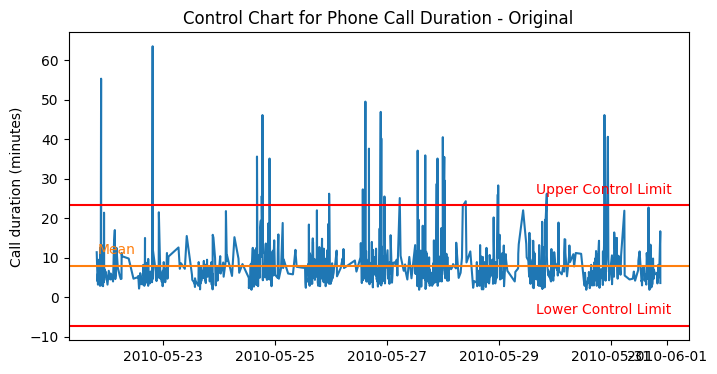

In [74]:
#Non-transformed control chart. 
y = new_parsed_df['Parsed Call Received'].values
mean = np.mean(calls)
std  = np.std(calls)

upper_limit = mean + limit * std
lower_limit = mean - limit * std
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(y, calls)

ax.axhline(mean, color='C1')
ax.axhline(upper_limit, color='r')
ax.axhline(lower_limit, color='r');
ax.text(y[-200], upper_limit + 3, 'Upper Control Limit', color='r')
ax.text(y[-200], lower_limit + 3, 'Lower Control Limit', color='r')
ax.text(y[3], mean + 3, 'Mean', color='C1')
ax.set_ylabel('Call duration (minutes)');
ax.set_title('Control Chart for Phone Call Duration - Original');

This isn't super helpful. The lower limits are negative, the control limits seem random. Not great. 

We can make one with transformed data. 

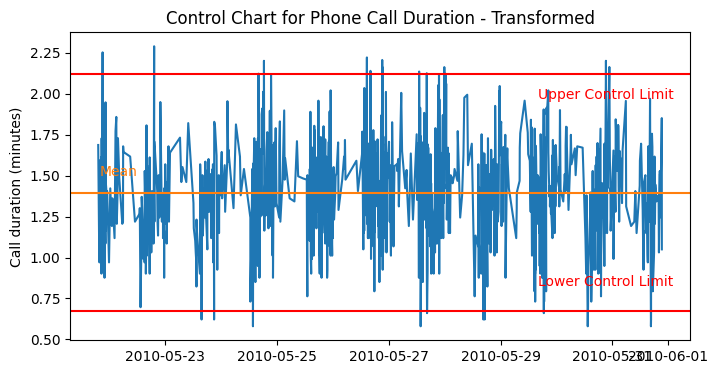

In [75]:
#Transformed control chart. 
mean_trans = np.mean(transCalls)
std_trans  = np.std(transCalls)

upper_limit_trans = mean_trans + limit * std_trans
lower_limit_trans = mean_trans - limit * std_trans
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(y, transCalls)

ax.axhline(mean_trans, color='C1')
ax.axhline(upper_limit_trans, color='r')
ax.axhline(lower_limit_trans, color='r');
ax.text(y[-200], upper_limit_trans - 0.15, 'Upper Control Limit', color='r')
ax.text(y[-200], lower_limit_trans + 0.15, 'Lower Control Limit', color='r')
ax.text(y[3], mean_trans + 0.1, 'Mean', color='C1')
ax.set_ylabel('Call duration (minutes)');
ax.set_title('Control Chart for Phone Call Duration - Transformed');

Way better! Now the control lines are useful. This is something that is really done in practice. 

Now, we don't really care about the transformed data specifically, we care about the real values. How do we go backwards? Call the inverse transformation. 

<Axes: ylabel='Count'>

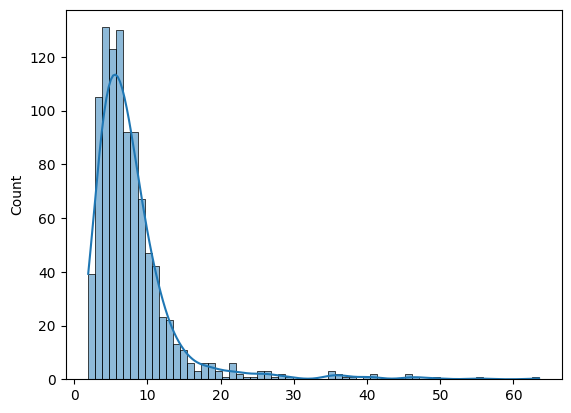

In [76]:
#Reverse the transformation. 
from scipy.special import inv_boxcox
backTrans = inv_boxcox(transCalls, lmbda)
sns.histplot(backTrans, kde=True)

Voila! Back where we started. 

Why? We can transform some data to make it normal to utilize any normal-based analysis on the data. We can more easily do hypothesis testing, control charts, confidence intervals, etc...

Using the benefits of normality can help us out!

## Imputation - Simply

<b>Note:</b> In all of the exercises/examples down below I had a lot of variance in results from run to run, don't worry much about specific values because of that. 

When we looked at encoding, we encountered a basic issue - we need numbers to do math. Encoding changed categorical data into a numerical representation, so our ML algorithms could use that data. Similarly, what if we have missing data? We also can't do math with blank spaces, so we need a similar approach. Imputation is the process of filling, imputing, a value for missing data.

### Simple Imputater

There are many ways that we could impute data, with varying levels of complexity. To handle simple scenarios, we can use the SimpleImputer class from sklear, which allows us to impute data by inserting one of the following:
<ul>
<li>Mean</li>
<li>Median</li>
<li>Mode</li>
<li>Constant - a constant value that we specify</li>
</ul>

The setting of what to impute can be controled via a parameter. 

In [77]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, PowerTransformer
from sklearn.impute import SimpleImputer
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error

dfImpute = pd.read_csv("data/fifa_eda.csv")
dfImpute.isna().sum()

ID                            0
Name                          0
Age                           0
Nationality                   0
Overall                       0
Potential                     0
Club                        241
Value                       252
Wage                          0
Preferred Foot                0
International Reputation     48
Skill Moves                  48
Position                      0
Joined                        0
Contract Valid Until        289
Height                        0
Weight                        0
Release Clause                0
dtype: int64

#### Example - Missing Data

The dataset above has some missing data, so we can impute it. The process is identical for basically any type of dataset, there isn't much that changes other than choosing the strategy of what to impute. 

##### Exploration - What do we Have?

We can start with exploring the data a little, other than just the null counts. 

In [78]:
dfImpute.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18207 non-null  int64  
 1   Name                      18207 non-null  object 
 2   Age                       18207 non-null  int64  
 3   Nationality               18207 non-null  object 
 4   Overall                   18207 non-null  int64  
 5   Potential                 18207 non-null  int64  
 6   Club                      17966 non-null  object 
 7   Value                     17955 non-null  float64
 8   Wage                      18207 non-null  float64
 9   Preferred Foot            18207 non-null  object 
 10  International Reputation  18159 non-null  float64
 11  Skill Moves               18159 non-null  float64
 12  Position                  18207 non-null  object 
 13  Joined                    18207 non-null  int64  
 14  Contra

In [79]:
dfImpute.sample(20)

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
7255,181917,L. Noriega,33,Mexico,68,68,Tiburones Rojos de Veracruz,525.0,4.0,Right,1.0,3.0,LDM,2018,2019-01-01,5.666667,161.000000,866.000000
14725,225051,B. Warland,21,Australia,60,69,Sydney FC,280.0,1.0,Left,1.0,2.0,CB,2018,2019-01-01,6.083333,181.000000,406.000000
10939,225016,G. Di Noia,23,Italy,65,71,Carpi,725.0,4.0,Left,1.0,3.0,CM,2016,2019-06-30,5.916667,159.000000,4585.060806
13272,240701,L. Spence,22,Scotland,62,70,Dundee FC,450.0,1.0,Right,NaN,NaN,LB,2016,NaN,5.946771,165.979129,4585.060806
4354,230522,Nascimentardo,30,Brazil,71,71,Ceará Sporting Club,2200.0,14.0,Right,1.0,3.0,RAM,2018,2020-01-01,5.583333,146.000000,4100.000000
4576,188107,A. Diomande,28,Norway,71,71,Los Angeles FC,2400.0,7.0,Right,1.0,3.0,ST,2018,2020-01-01,5.916667,179.000000,3700.000000
5663,176645,Z. Zlámal,32,Czech Republic,69,69,Heart of Midlothian,600.0,3.0,Right,1.0,1.0,GK,2018,2021-01-01,6.333333,203.000000,1100.000000
18184,241657,D. Horton,18,England,48,55,Lincoln City,40.0,1.0,Right,1.0,2.0,CM,2017,2021-01-01,6.083333,179.000000,78.000000
4266,234078,O. Mangala,20,Belgium,71,82,Hamburger SV,4000.0,15.0,Right,1.0,3.0,CDM,2016,2019-06-30,5.833333,172.000000,4585.060806
10549,201112,J. Słowik,26,Poland,65,67,Śląsk Wrocław,450.0,2.0,Right,1.0,1.0,GK,2017,2019-01-01,6.250000,181.000000,641.000000


<Axes: xlabel='Wage', ylabel='Count'>

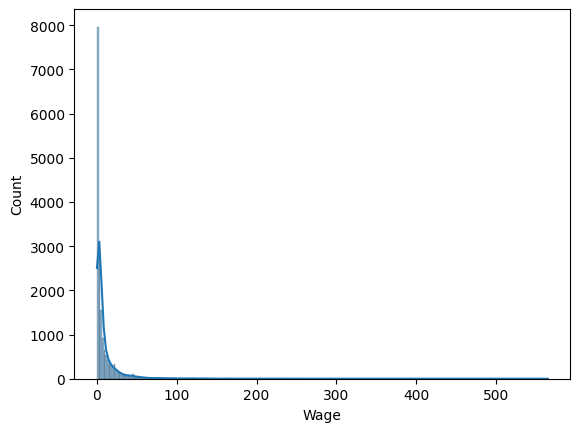

In [80]:
sns.histplot(dfImpute["Wage"], kde=True)

In [81]:
dfImpute["Contract Valid Until"].sample(20)

13353    2021-01-01
7349     2020-01-01
4986     2023-01-01
5047     2021-01-01
15741    2023-01-01
3966     2021-01-01
8522     2023-01-01
12533    2018-01-01
12668    2020-01-01
9410     2020-01-01
6943     2019-01-01
16905    2021-01-01
12816    2021-01-01
6705     2021-01-01
4739     2022-01-01
16484    2021-01-01
5744     2022-01-01
11159    2020-01-01
6583     2019-01-01
5659     2020-01-01
Name: Contract Valid Until, dtype: object

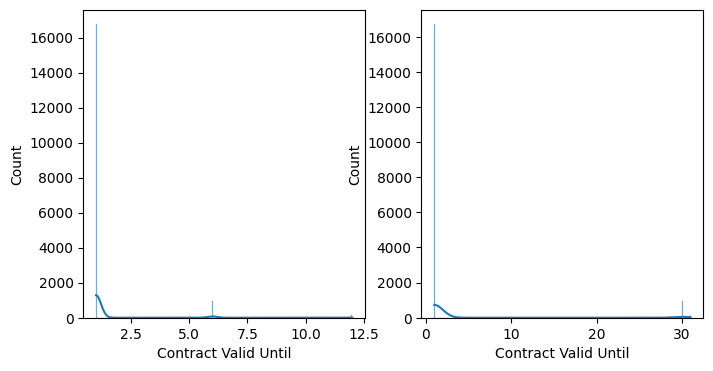

In [82]:
dfImpute["Contract Valid Until"] = pd.to_datetime(dfImpute["Contract Valid Until"], format='%Y-%m-%d')
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
months = dfImpute["Contract Valid Until"].dt.month
days = dfImpute["Contract Valid Until"].dt.day
sns.histplot(months, kde=True, ax=ax[0])
sns.histplot(days, kde=True, ax=ax[1])
dfImpute["Contract Valid Until"] = dfImpute["Contract Valid Until"].dt.year
dfImpOrig = dfImpute.copy()
dfImpute["Contract Valid Until"] = dfImpute["Contract Valid Until"].astype("Int64")

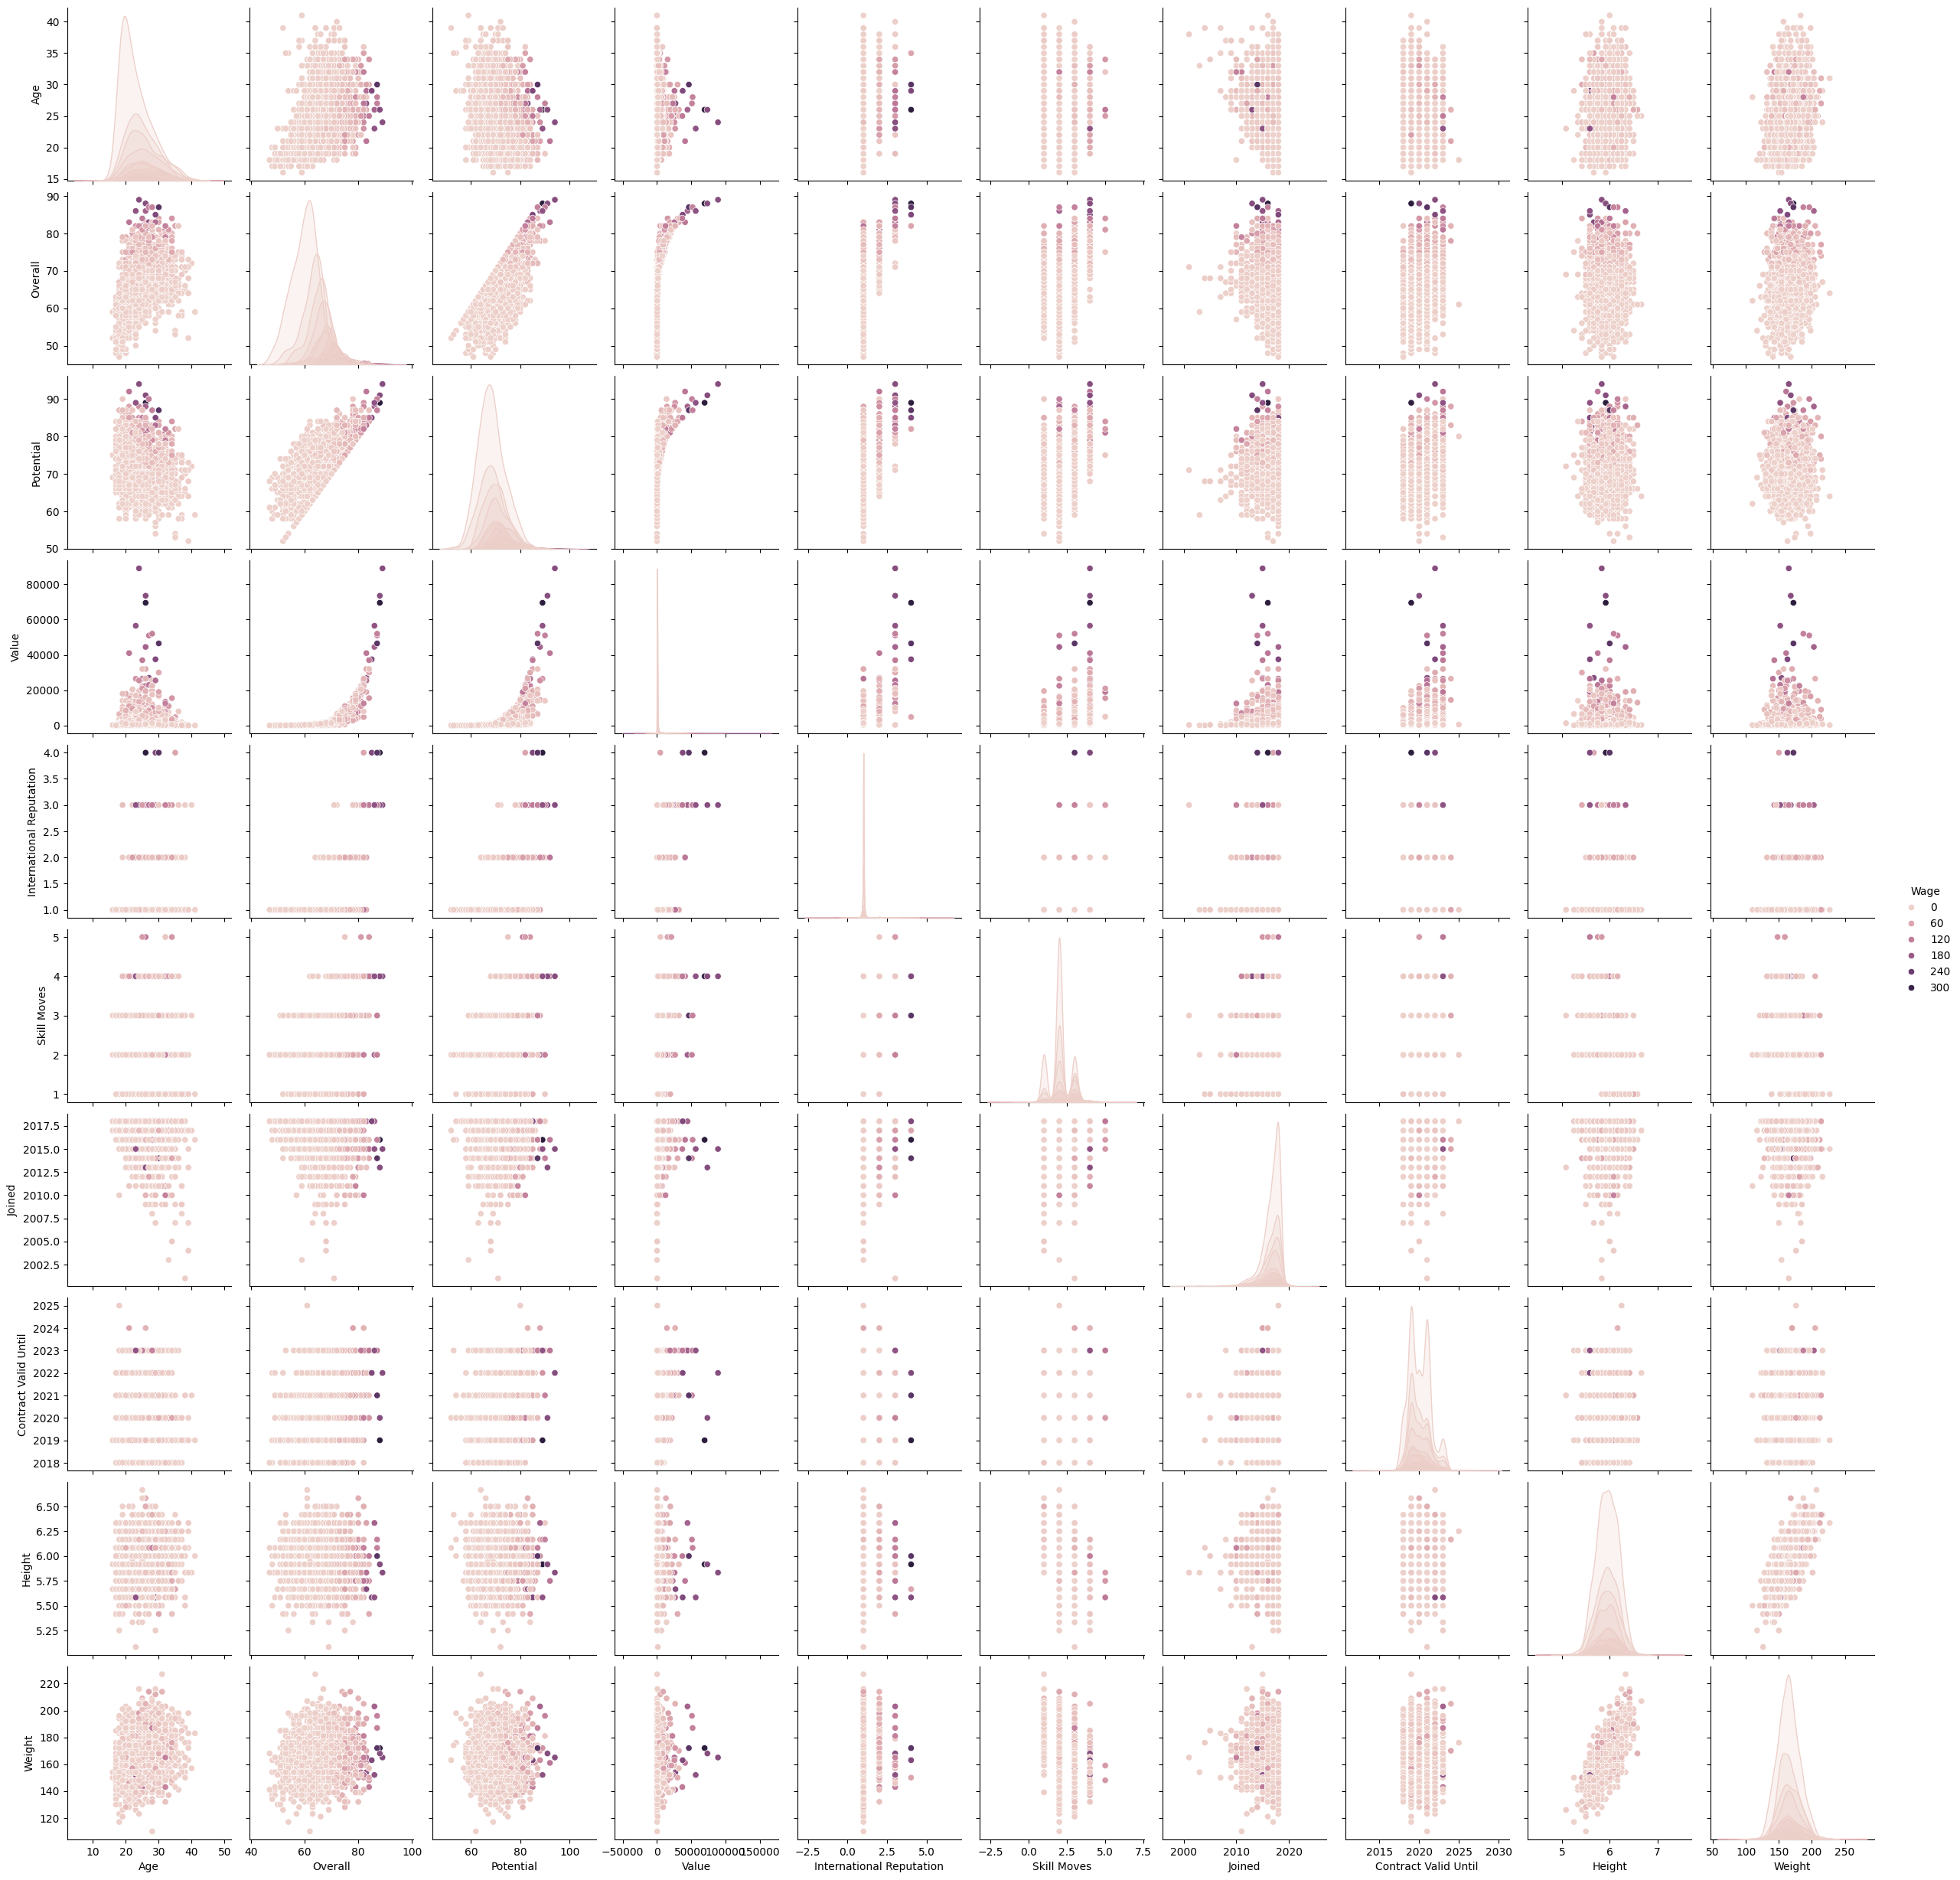

In [83]:
ppColumnsDrop = ["ID", "Name", "Release Clause", "Nationality"]
ppSampleRate = .1
sns.pairplot(dfImpute.drop(columns=ppColumnsDrop).sample(frac=ppSampleRate), hue="Wage")

In [84]:
catCols = dfImpute.select_dtypes(include="object").columns
otherDropCols = ["ID", "Nationality"]
combinedDrop = list(catCols) + list(otherDropCols)
dfToProcess = dfImpute.drop(columns=combinedDrop)

#### Cleanup

From the exploration above, there are a few things that I want to do:
<ul>
<li> The date appears to be able to be represetned with just the year. We are doing numerical work, so this is much easier.</li>
<li></li>
<li> There are a couple of pretty skewed/low-variance colums - wage, internation reputation, and joined at a minimum. </li>
<li> There are some categorical columns, so we'll drop them. We can use them after we do ColumnTransformers </li>
<li> We have some missing data, so we can impute!</li>
</ul>

#### Baseline - Drop Imputation

We can set a quick baseline by dropping the rows with missing data, and seeing how well we do. 

In [85]:
resultCols = ["Model Name", "R2", "RMSE"]
resultDF = pd.DataFrame(columns=resultCols)

In [86]:
dfBaseline = dfToProcess.dropna()

y_base = dfBaseline["Wage"]
X_base = dfBaseline.drop(columns=["Wage"])

X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(X_base, y_base, test_size=0.2)

pipe_base = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

model_base = pipe_base.fit(X_train_base, y_train_base)
base_score = model_base.score(X_test_base, y_test_base)
base_rmse = root_mean_squared_error(y_test_base, model_base.predict(X_test_base))
resultDF = pd.concat([resultDF, pd.DataFrame([["Baseline", base_score, base_rmse]], columns=resultCols)], ignore_index=True)
print("Data Shapes: \nX_train_base:", X_train_base.shape, "X_test_base:", X_test_base.shape, "\ny_train_base:", y_train_base.shape, "y_test_base:", y_test_base.shape)
print("Baseline Score:", base_score)


Data Shapes: 
X_train_base: (14325, 11) X_test_base: (3582, 11) 
y_train_base: (14325,) y_test_base: (3582,)
Baseline Score: 0.77110947536519


/tmp/ipykernel_59132/766305155.py:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  resultDF = pd.concat([resultDF, pd.DataFrame([["Baseline", base_score, base_rmse]], columns=resultCols)], ignore_index=True)


#### Imputation Considerations

When we impute data, we are *literally* generating and inserting fake data, this has an impact on our analysis. There are some considerations to keep in mind when imputing data:
<ul>
<li> What is the meaning of the data, in the real world? This requires some domain knowledge to do well, we need to consider how our imputation makes sense in reality. </li>
<li> What is the distribution of the data? If we impute with a mean, but the data is bimodal, we are inserting a value that doesn't really exist in the population. </li>
<li> How much data is missing? If we are missing a lot of data, we may be better off just dropping the column instead of imputing. </li>
</ul>

#### Pipeline

We can construct a pipeline to do this for us. In theory, we could do any parts that we don't know how to implement in a pipeline by hand, then use the pipeline to do the rest. The pipeline is a better solution though, so we'll try to do as much as possible in the pipeline.

I'll start with steps that can correct some stuff I noticed above:
<ul>
<li> Impute - there is missing data, we must fill it. </li>
<li> Scale - columns have different ranges, so we need to scale them for better performance. </li>
<li> Transform - some columns are skewed, so we can transform them to be more normal. </li>
</ul>

At this point, I think that's what we need - I don't notice outliers or multicollinearity, so we can proceed. If we ever need to update things and make the preprocessing more complex, we can always just come back and add a step to the pipeline before rerunning it. 

In [87]:
pipelineMean = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("transformer", PowerTransformer()),
    ("scaler", MinMaxScaler()),
    ("regModel", LinearRegression())
])

y_Imp = dfToProcess["Wage"]
X_Imp = dfToProcess.drop(columns=["Wage"])

X_train, X_test, y_train, y_test = train_test_split(X_Imp, y_Imp, test_size=0.2)

impModel = pipelineMean.fit(X_train, y_train)
impModelScore = impModel.score(X_test, y_test)
impModelRMSE = root_mean_squared_error(y_test, impModel.predict(X_test))
resultDF = pd.concat([resultDF, pd.DataFrame([["Imputation Model (Mean)", impModelScore, impModelRMSE]], columns=resultCols)], ignore_index=True)
print("Data Shapes:")
print("Training Data:", X_train.shape, y_train.shape)
print("Testing Data:", X_test.shape, y_test.shape)
print("Imputation Model Score:", impModelScore)

Data Shapes:
Training Data: (14565, 11) (14565,)
Testing Data: (3642, 11) (3642,)
Imputation Model Score: 0.4097640373278667


In [88]:
pipelineMed = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("transformer", PowerTransformer()),
    ("scaler", MinMaxScaler()),
    ("regModel", LinearRegression())
])

y_Imp = dfToProcess["Wage"]
X_Imp = dfToProcess.drop(columns=["Wage"])

X_train, X_test, y_train, y_test = train_test_split(X_Imp, y_Imp, test_size=0.2)

impModel = pipelineMed.fit(X_train, y_train)
impModelScore = impModel.score(X_test, y_test)
impModelRMSE = root_mean_squared_error(y_test, impModel.predict(X_test))
resultDF = pd.concat([resultDF, pd.DataFrame([["Imputation Model (Medi)", impModelScore, impModelRMSE]], columns=resultCols)], ignore_index=True)
print("Data Shapes:")
print("Training Data:", X_train.shape, y_train.shape)
print("Testing Data:", X_test.shape, y_test.shape)
print("Imputation Model Score:", impModelScore)

Data Shapes:
Training Data: (14565, 11) (14565,)
Testing Data: (3642, 11) (3642,)
Imputation Model Score: 0.43544352625662863


#### Results - Why

The results are (in most trials), pretty bad. Any ideas why? 

I have a theory that the Value imputation is distorting that value, and is hurting performance. I'll test this a little at the very bottom. 

## Example - Keep Categorical (by Hand)

We can also keep the categorical data, even though we don't have a ColumnTransformer yet, it is just more annoying.

In [89]:
dfImpOrig.head(5)

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,110500.0,565.0,Left,5.0,4.0,RF,2004,2021.0,5.583333,159.0,226500.0
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,77000.0,405.0,Right,5.0,5.0,ST,2018,2022.0,6.166667,183.0,127100.0
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,118500.0,290.0,Right,5.0,5.0,LW,2017,2022.0,5.750000,150.0,228100.0
3,193080,De Gea,27,Spain,91,93,Manchester United,72000.0,260.0,Right,4.0,1.0,GK,2011,2020.0,6.333333,168.0,138600.0
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,102000.0,355.0,Right,4.0,4.0,RCM,2015,2023.0,5.916667,154.0,196400.0


In [90]:
keepClub = True
dfImpCat = dfImpOrig.drop(columns=["Name", "ID"])
if not keepClub:
    dfImpCat = dfImpCat.drop(columns=["Club"])
dfImpCat.head()

,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
0,31,Argentina,94,94,FC Barcelona,110500.0,565.0,Left,5.0,4.0,RF,2004,2021.0,5.583333,159.0,226500.0
1,33,Portugal,94,94,Juventus,77000.0,405.0,Right,5.0,5.0,ST,2018,2022.0,6.166667,183.0,127100.0
2,26,Brazil,92,93,Paris Saint-Germain,118500.0,290.0,Right,5.0,5.0,LW,2017,2022.0,5.750000,150.0,228100.0
3,27,Spain,91,93,Manchester United,72000.0,260.0,Right,4.0,1.0,GK,2011,2020.0,6.333333,168.0,138600.0
4,27,Belgium,91,92,Manchester City,102000.0,355.0,Right,4.0,4.0,RCM,2015,2023.0,5.916667,154.0,196400.0


##### Pipeline - With Encoding up Front!

We can now prep the data for modeling, with a little extra work to handle the categorical data before the pipeline starts. 

In [91]:
y_cat = dfImpCat["Wage"]
X_cat = dfImpCat.drop(columns=["Wage"])
X_cat = pd.get_dummies(X_cat, drop_first=True)

X_cat_train, X_cat_test, y_cat_train, y_cat_test = train_test_split(X_cat, y_cat, test_size=0.2)
print("Shapes:")
print(f"X_cat_train: {X_cat_train.shape}, y_cat_train: {y_cat_train.shape}")
print(f"X_cat_test: {X_cat_test.shape}, y_cat_test: {y_cat_test.shape}")

Shapes:
X_cat_train: (14565, 851), y_cat_train: (14565,)
X_cat_test: (3642, 851), y_cat_test: (3642,)


In [92]:
pipe_cat = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("transformer", PowerTransformer()),
    ("scaler", MinMaxScaler()),
    ("regModel", LinearRegression())
])
print("Data Shapes:")
print("Training Data:", X_cat_train.shape, y_cat_train.shape)
print("Testing Data:", X_cat_test.shape, y_cat_test.shape)
model_cat = pipe_cat.fit(X_cat_train, y_cat_train)
model_cat_score = model_cat.score(X_cat_test, y_cat_test)
model_cat_rmse = root_mean_squared_error(y_cat_test, model_cat.predict(X_cat_test))
resultDF = pd.concat([resultDF, pd.DataFrame([["Categorical Model", model_cat_score, model_cat_rmse]], columns=resultCols)], ignore_index=True)
print("Categorical Model Score:", model_cat_score)

Data Shapes:
Training Data: (14565, 851) (14565,)
Testing Data: (3642, 851) (3642,)
Categorical Model Score: 0.7148581180894806


##### Compare Imputation

We can make another pipeline to compare the results of imputing with different options. It isn't in this example, but we can also try different scaling in basically the same way. 

In [93]:
pipe_cat_2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("transformer", PowerTransformer()),
    ("scaler", StandardScaler()),
    ("regModel", LinearRegression())
])
print("Data Shapes:")
print("Training Data:", X_cat_train.shape, y_cat_train.shape)
print("Testing Data:", X_cat_test.shape, y_cat_test.shape)
model_cat_2 = pipe_cat_2.fit(X_cat_train, y_cat_train)
model_cat_2_score = model_cat_2.score(X_cat_test, y_cat_test)
model_cat_2_rmse = root_mean_squared_error(y_cat_test, model_cat_2.predict(X_cat_test))
resultDF = pd.concat([resultDF, pd.DataFrame([["Categorical Model (Med)", model_cat_2_score, model_cat_2_rmse]], columns=resultCols)], ignore_index=True)
print("Categorical Model 2 Score:", model_cat_2_score)

Data Shapes:
Training Data: (14565, 851) (14565,)
Testing Data: (3642, 851) (3642,)
Categorical Model 2 Score: 0.7161944266940823


In [94]:
dfResults = resultDF.sort_values(by="R2", ascending=False)
dfResults.head(10)

,Model Name,R2,RMSE
0,Baseline,0.771109,10.985607
4,Categorical Model (Med),0.716194,9.830069
3,Categorical Model,0.714858,9.853185
2,Imputation Model (Medi),0.435444,18.072271
1,Imputation Model (Mean),0.409764,17.740945


## Exercise - Predict Charges

In [95]:
dfEx = pd.read_csv("data/insurance.csv")
dfEx.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


#### Transform Target

Now try with a transformed target. 

<b>Note:</b> Check the solution for example of a completed version, until then, try to do it based on reference materials. 

## Exercise - Predict PER

PER is a basketball statistic that is kind of like a single overall ranking of a player. Use whatever data you want to build a regression model that predicts PER. Once you get a model working, try some things to observe the results. 

In [106]:
df2 = pd.read_csv("data/NBA.csv")

team_stats = df2.groupby("Team")[["MIN", "PTS", "FGM", "FGA", "FTM", "FTA", "OREB", "REB", "AST", "STL", "BLK", "TOV", "PF"]].sum()
league_stats = df2[["PTS", "FGM", "FGA", "FTM", "FTA", "OREB", "REB", "AST", "TOV", "PF"]].sum()

# Estimate team pace from box-score totals because the table has no official pace data.
team_stats["Possessions"] = team_stats["FGA"] - team_stats["OREB"] + team_stats["TOV"] + 0.44 * team_stats["FTA"]
team_stats["Games"] = team_stats["MIN"] / 240
team_stats["Pace"] = team_stats["Possessions"] / team_stats["Games"]
league_pace = team_stats["Possessions"].sum() / team_stats["Games"].sum()

factor = (2 / 3) - (0.5 * (league_stats["AST"] / league_stats["FGM"])) / (2 * (league_stats["FGM"] / league_stats["FTM"]))
vop = league_stats["PTS"] / (league_stats["FGA"] - league_stats["OREB"] + league_stats["TOV"] + 0.44 * league_stats["FTA"])
drb_pct = (league_stats["REB"] - league_stats["OREB"]) / league_stats["REB"]
team_ast_fg = df2["Team"].map(team_stats["AST"] / team_stats["FGM"])

uper = (
    df2["3PM"]
    + (2 / 3) * df2["AST"]
    + (2 - factor * team_ast_fg) * df2["FGM"]
    + df2["FTM"] * 0.5 * (1 + (1 - team_ast_fg) + (2 / 3) * team_ast_fg)
    - vop * df2["TOV"]
    - vop * drb_pct * (df2["FGA"] - df2["FGM"])
    - vop * 0.44 * (0.44 + 0.56 * drb_pct) * (df2["FTA"] - df2["FTM"])
    + vop * (1 - drb_pct) * (df2["REB"] - df2["OREB"])
    + vop * drb_pct * df2["OREB"]
    + vop * df2["STL"]
    + vop * drb_pct * df2["BLK"]
    - df2["PF"] * ((league_stats["FTM"] / league_stats["PF"]) - 0.44 * (league_stats["FTA"] / league_stats["PF"]) * vop)
) / df2["MIN"]

aper = uper * df2["Team"].map(league_pace / team_stats["Pace"])
league_aper = (aper * df2["MIN"]).sum() / df2["MIN"].sum()
df2["PER"] = aper * (15 / league_aper)
df2.head()

,Name,Games Played,MIN,PTS,FGM,FGA,FG%,3PM,3PA,3P%,...,Birth_Place,Birthdate,Collage,Experience,Height,Pos,Team,Weight,BMI,PER
0,AJ Price,26,324,133,51,137,37.2,15,57,26.3,...,us,"October 7, 1986",University of Connecticut,5,185.0,PG,PHO,81.45,23.798393,11.860418
1,Aaron Brooks,82,1885,954,344,817,42.1,121,313,38.7,...,us,"January 14, 1985",University of Oregon,6,180.0,PG,CHI,72.45,22.361111,16.252743
2,Aaron Gordon,47,797,243,93,208,44.7,13,48,27.1,...,us,"September 16, 1995",University of Arizona,R,202.5,PF,ORL,99.00,24.142661,12.908229
3,Adreian Payne,32,740,213,91,220,41.4,1,9,11.1,...,us,"February 19, 1991",Michigan State University,R,205.0,PF,ATL,106.65,25.377751,8.474521
4,Al Horford,76,2318,1156,519,965,53.8,11,36,30.6,...,do,"June 3, 1986",University of Florida,7,205.0,C,ATL,110.25,26.234384,24.362936


Go Predict!!

### From Above - Testing My Theory

I think that Value might be the cause here - I suspect it is a good predictor, and often missing. 

In [111]:
y_noValue = dfImpCat["Wage"]
X_noValue = dfImpCat.drop(columns=["Wage", "Value"])
X_noValue = pd.get_dummies(X_noValue, drop_first=True)

In [112]:
pipe_val_no_imp = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("transformer", PowerTransformer()),
    ("scaler", MinMaxScaler()),
    ("regModel", LinearRegression())
])

X_train_val_no_imp, X_test_val_no_imp, y_train_val_no_imp, y_test_val_no_imp = train_test_split(X_noValue, y_noValue, test_size=0.2)

val_no_imp_model = pipe_val_no_imp.fit(X_train_val_no_imp, y_train_val_no_imp)
val_no_imp_model_score = val_no_imp_model.score(X_test_val_no_imp, y_test_val_no_imp)
val_no_imp_model_rmse = root_mean_squared_error(y_test_val_no_imp, val_no_imp_model.predict(X_test_val_no_imp))
print("Model Score:", val_no_imp_model_score)
print("Model RMSE:", val_no_imp_model_rmse)
resultDF = pd.concat([resultDF, pd.DataFrame([["No Value Column", val_no_imp_model_score, val_no_imp_model_rmse]], columns=resultCols)], ignore_index=True)
resultDF = resultDF.sort_values(by="R2", ascending=False)
resultDF.head(10)

Model Score: 0.672851184644266
Model RMSE: 12.490205545094414


,Model Name,R2,RMSE
0,Baseline,0.771109,10.985607
4,Categorical Model (Med),0.716194,9.830069
3,Categorical Model,0.714858,9.853185
5,No Value Column,0.672851,12.490206
2,Imputation Model (Medi),0.435444,18.072271
1,Imputation Model (Mean),0.409764,17.740945
